# Heart Disease Prediction using Machine Learning

**Course:** Fundamentals of Machine Learning – Programming Assignment
**Group members:** *MS26923406*, *MS26923338*
**Dataset:** UCI Heart Disease Dataset (Cleveland subset)
**Dataset source:** https://archive.ics.uci.edu/dataset/45/heart+disease  

**Problem:** Predict whether a patient has heart disease from clinical measurements (binary classification, supervised learning).

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

RANDOM_STATE = 42
sns.set_style("whitegrid")

## Load the dataset
The loader tries the `ucimlrepo` package first, then the raw UCI file

In [42]:
COLS = ["age","sex","cp","trestbps","chol","fbs","restecg","thalach","exang","oldpeak","slope","ca","thal","target"]

def load_data():

    # Try loading the dataset using ucimlrepo
    try:
        from ucimlrepo import fetch_ucirepo
        hd = fetch_ucirepo(id=45)
        df = pd.concat([hd.data.features, hd.data.targets], axis=1)
        df.columns = COLS
        print("Loaded via ucimlrepo")
        return df
    except Exception as e:
        print("ucimlrepo failed:", type(e).__name__)

    # Try loading the dataset directly from the UCI website
    try:
        url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
        df = pd.read_csv(url, header=None, names=COLS, na_values="?")
        print("Loaded from UCI URL")
        return df
    except Exception as e:
        print("UCI URL failed:", type(e).__name__)

df = load_data()

# Convert values to numbers and turn invalid values into missing values.
df = df.apply(pd.to_numeric, errors="coerce")

print("Dataset shape:", df.shape)
display(df.head())

Loaded via ucimlrepo
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## Prepare the data

The original target (`target`, also called `num` in the source dataset) uses values from 0 to 4. We convert it to a binary target: **0 = no heart disease** and **1 = heart disease present**.


In [43]:
df = df.dropna(subset=["target"]).copy()
df["target"] = (df["target"] > 0).astype(int)

print("Dataset rows and columns:", df.shape)
print("\nMissing values by column:")
missing_values = df.isna().sum()
print(missing_values[missing_values > 0] if missing_values.any() else "No missing values found.")

print("\nClass counts:")
print(df["target"].value_counts().sort_index().rename(index={0: "No disease", 1: "Disease"}))

print("\nClass proportions:")
print(df["target"].value_counts(normalize=True).sort_index().round(3).rename(index={0: "No disease", 1: "Disease"}))

display(df.describe().T.round(2))

Dataset rows and columns: (303, 14)

Missing values by column:
ca      4
thal    2
dtype: int64

Class counts:
target
No disease    164
Disease       139
Name: count, dtype: int64

Class proportions:
target
No disease    0.541
Disease       0.459
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


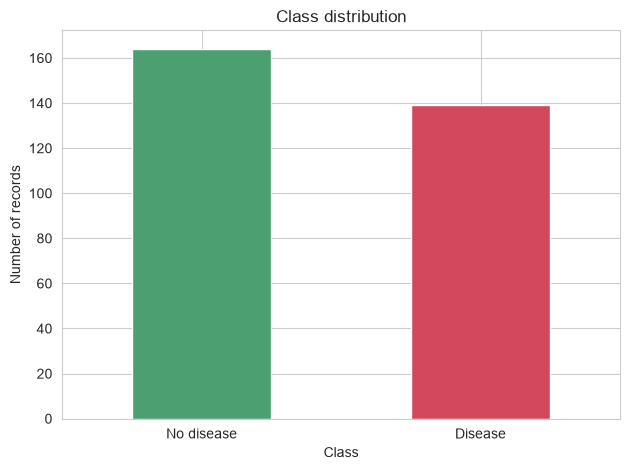

In [44]:
df["target"].value_counts().sort_index().plot(
    kind="bar", color=["#4C9F70", "#D1495B"]
)

plt.xticks([0, 1], ["No disease", "Disease"], rotation=0)
plt.title("Class distribution")
plt.ylabel("Number of records")
plt.xlabel("Class")

plt.tight_layout()
plt.show()

### Train/test split and preprocessing pipeline

- We keep 20% of the data for final testing and use stratification to preserve the class proportions.
- Numeric columns are imputed with the median and scaled.
- Categorical columns are imputed with the most frequent value and one-hot encoded.

In [45]:
X = df.drop(columns="target")
y = df["target"]
num_cols = ["age","trestbps","chol","thalach","oldpeak","ca"]
cat_cols = ["sex","cp","fbs","restecg","exang","slope","thal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

preprocess = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training records: 242
Testing records: 61


## Algorithm 1: Random Forest

In [46]:
rf_pipe = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(random_state=RANDOM_STATE, class_weight="balanced"))
])

rf_grid = {
    "clf__n_estimators": [100, 200],
    "clf__max_depth": [None, 4, 8],
    "clf__min_samples_leaf": [1, 3, 5],
    "clf__max_features": ["sqrt", "log2"],
}

rf_search = GridSearchCV(
    rf_pipe, rf_grid, cv=cv, scoring="f1", n_jobs=-1, refit=True
)
rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_

print("Best Random Forest parameters:", rf_search.best_params_)
print("Best training CV F1-score:", round(rf_search.best_score_, 4))

Best Random Forest parameters: {'clf__max_depth': 8, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}
Best training CV F1-score: 0.8025


## Algorithm 2: Support Vector Machine

In [47]:
svm_pipe = Pipeline([
    ("prep", preprocess), 
    ("clf", SVC(probability=True, random_state=RANDOM_STATE))
])

svm_grid = {
    "clf__C": [0.1, 1, 10, 100],
    "clf__gamma": ["scale", 0.01, 0.1],
    "clf__kernel": ["rbf", "linear"],
}

svm_search = GridSearchCV(svm_pipe, svm_grid, cv=cv, scoring="f1", n_jobs=-1)
svm_search.fit(X_train, y_train)

print("Best params:", svm_search.best_params_)
print("Best CV F1 :", round(svm_search.best_score_, 4))

svm_best = svm_search.best_estimator_

Best params: {'clf__C': 1, 'clf__gamma': 0.01, 'clf__kernel': 'rbf'}
Best CV F1 : 0.8273


## Final evaluation on the held-out test set

The following metrics are calculated from predictions on the test set, which was not used to tune the models. Because this is a medical classification example, recall is important to discuss alongside the other metrics.

In [48]:
def evaluate_model(name, model):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-score": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }

models = [("Random Forest", rf_best), ("SVM", svm_best)]
results = pd.DataFrame([evaluate_model(name, model) for name, model in models]).set_index("Model")
display(results.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.9016,0.8438,0.9643,0.9000,0.9513
SVM,0.9180,0.8966,0.9286,0.9123,0.9632


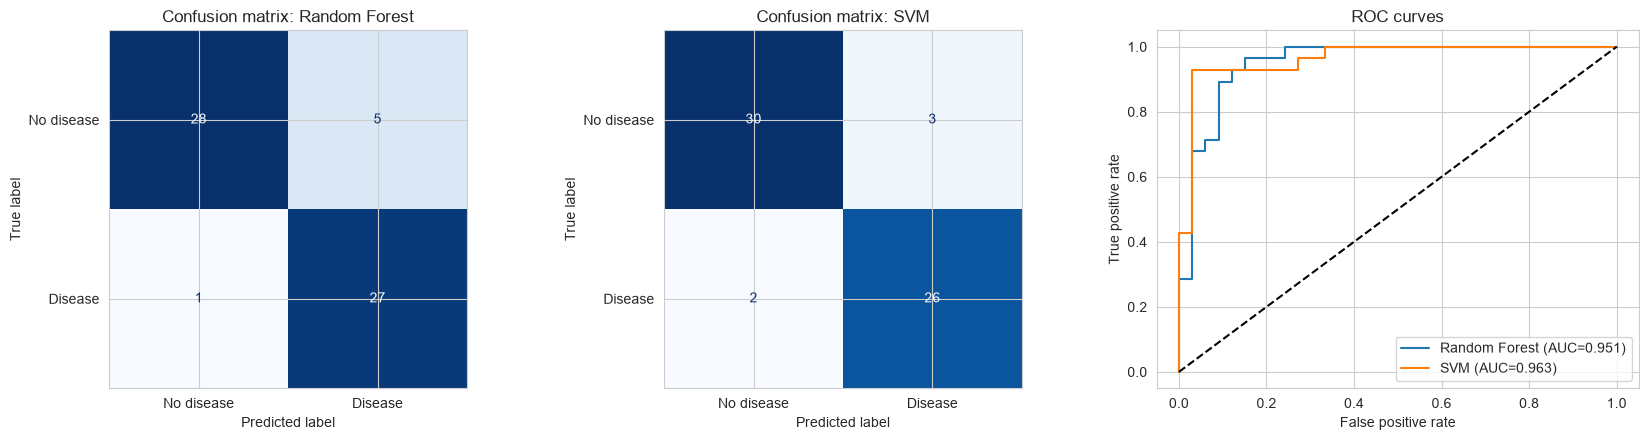

--- Random Forest ---
              precision    recall  f1-score   support

  No disease       0.97      0.85      0.90        33
     Disease       0.84      0.96      0.90        28

    accuracy                           0.90        61
   macro avg       0.90      0.91      0.90        61
weighted avg       0.91      0.90      0.90        61

--- SVM ---
              precision    recall  f1-score   support

  No disease       0.94      0.91      0.92        33
     Disease       0.90      0.93      0.91        28

    accuracy                           0.92        61
   macro avg       0.92      0.92      0.92        61
weighted avg       0.92      0.92      0.92        61



In [49]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for ax, (name, m) in zip(axes[:2], [("Random Forest", rf_best), ("SVM", svm_best)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, m.predict(X_test)),
                           display_labels=["No disease", "Disease"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Confusion matrix: {name}")
    
for name, m in [("Random Forest", rf_best), ("SVM", svm_best)]:
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, m.predict_proba(X_test)[:,1]):.3f})")
    
axes[2].plot([0, 1], [0, 1], "k--"); axes[2].set_xlabel("False positive rate"); axes[2].set_ylabel("True positive rate")
axes[2].set_title("ROC curves"); axes[2].legend()
plt.tight_layout(); plt.show()

for name, m in [("Random Forest", rf_best), ("SVM", svm_best)]:
    print(f"--- {name} ---")
    print(classification_report(y_test, m.predict(X_test), target_names=["No disease", "Disease"]))

### Cross-validation results used during tuning

The table below reports the mean and standard deviation of the **best F1-score across the five training folds** for each grid search. These scores helped select the hyperparameters; they are not a separate unbiased test of the final model. Use the held-out test-set table above for the final model comparison.

In [50]:
cv_rows = []
for name, search in [("Random Forest", rf_search), ("SVM", svm_search)]:
    best_index = search.best_index_
    cv_rows.append({
        "Model": name,
        "Best mean CV F1-score": search.cv_results_["mean_test_score"][best_index],
        "CV F1 standard deviation": search.cv_results_["std_test_score"][best_index],
    })

cv_summary = pd.DataFrame(cv_rows).set_index("Model")
display(cv_summary.round(4))

,Best mean CV F1-score,CV F1 standard deviation
Model,,
Random Forest,0.8025,0.0343
SVM,0.8273,0.0313


## 7. Feature importance

Random Forest provides an estimate of feature importance. These scores describe how much the fitted forest used each transformed feature; they do not prove that a feature causes heart disease. One-hot encoding means a single original categorical variable may appear as several features.

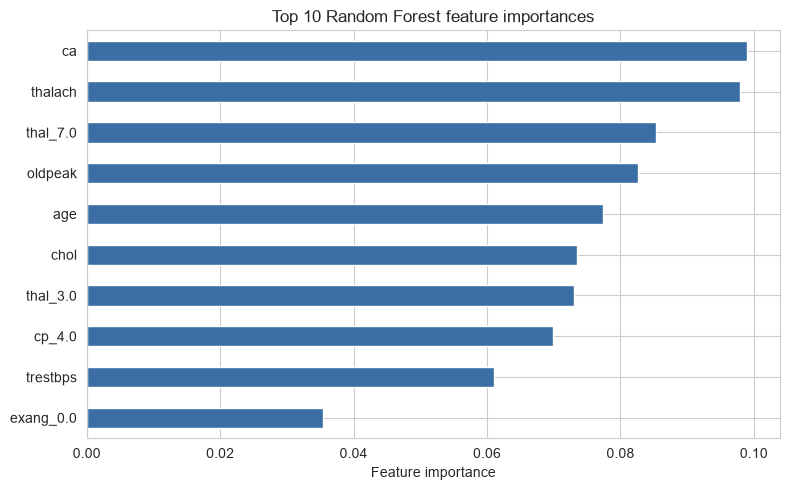

In [53]:
onehot_names = (
    rf_best.named_steps["prep"]
    .named_transformers_["cat"]
    .named_steps["oh"]
    .get_feature_names_out(cat_cols)
)

feature_names = num_cols + list(onehot_names)

importances = pd.Series(
    rf_best.named_steps["clf"].feature_importances_,
    index=feature_names
).sort_values(ascending=False).head(10)

importances.sort_values().plot(
    kind="barh", figsize=(8, 5), color="#3A6EA5"
)

plt.xlabel("Feature importance")
plt.title("Top 10 Random Forest feature importances")
plt.tight_layout()
plt.show()